In [1]:
%pip install -q diffusers transformers accelerate safetensors

Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch
from diffusers import StableDiffusionXLPipeline

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

pipe = StableDiffusionXLPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    torch_dtype=dtype,
    use_safetensors=True,
)
pipe = pipe.to(device)

/home/infres/yrothlin-24/.local/share/mamba/envs/rech202/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading pipeline components...: 100%|██████████| 7/7 [00:20<00:00,  2.96s/it]


100%|██████████| 30/30 [00:01<00:00, 17.03it/s]
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


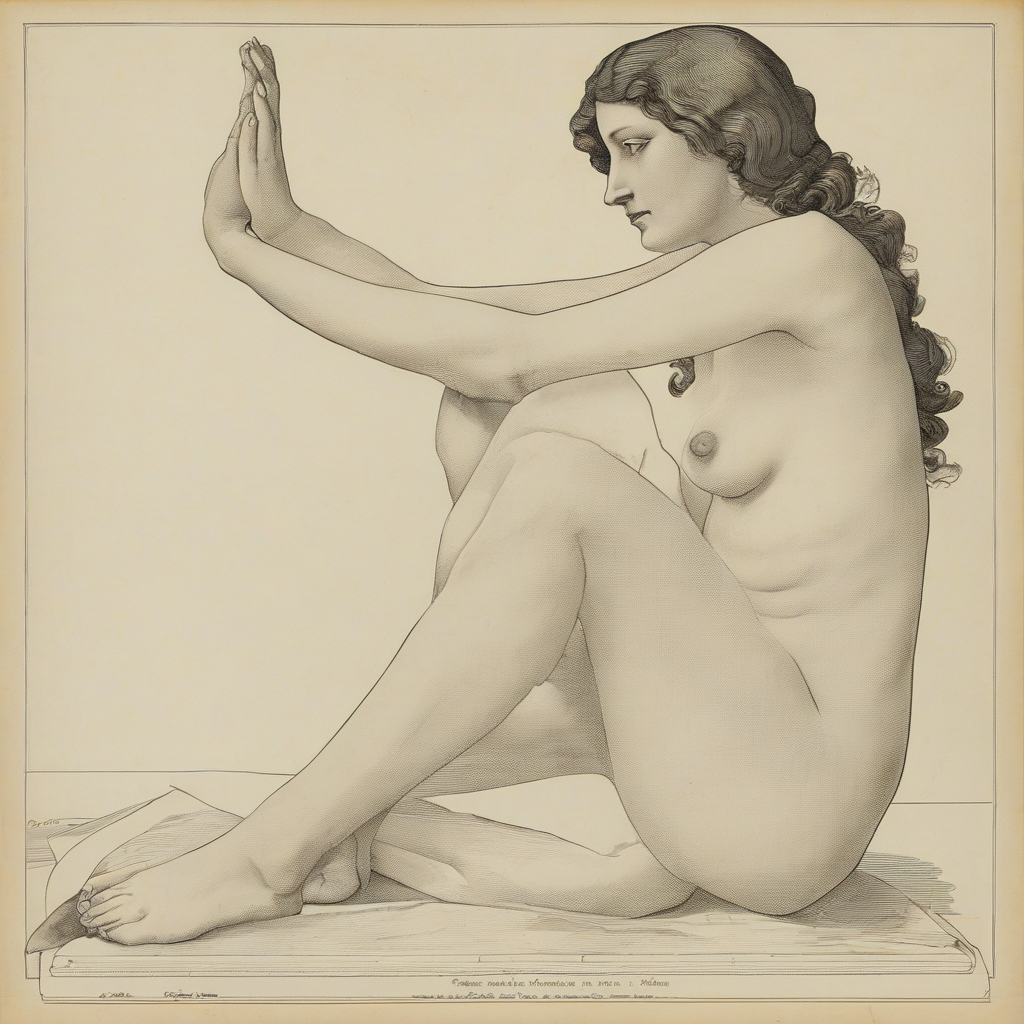

In [15]:
prompt = "blur."
negative_prompt = "blurry, low quality, distorted"

generator = torch.Generator(device=device).manual_seed(42)

image = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    num_inference_steps=30,
    guidance_scale=7.5,
    generator=generator,
).images[0]

image